In [1]:
# Import the libraries
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np

# Demonstrator 1 - Diffusive and dispersive schemes for a gaussian signal

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

In [405]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00



cd /"$DIR"

#We have to remove any file with the same name before running the simulation out of precaution
rm CANAL_gauss_ubs.*
rm CANAL_gauss_fct2.*
rm CANAL_gauss_fct4.*

chmod -R a+x /"$DIR"/demo_gauss/

bash /"$DIR"/demo_gauss/gauss_istate.sh "$DIR"
bash /"$DIR"/demo_gauss/gauss_cfg.sh "$DIR"
bash /"$DIR"/demo_gauss/lambda_run.sh "$DIR" "25 50 100 200"
    

106a107
>             pts(:,:,jk,jp_sal) = 30._wp+5._wp*EXP( -0.5_wp *glamt(:,:)**2 / rn_lambda**2 )
Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
Compilation form : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
-e 



You are compiling an existing configuration EXP42 with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for EXP42

Process is interrupted.


In [2]:
#Insert below the name of the directory in which you will run the simulations /.../EXP$$
rep = ''


In [3]:
lambda_list = [25, 50, 100, 200]
scheme_list = ['ubs', 'fct2', 'fct4']

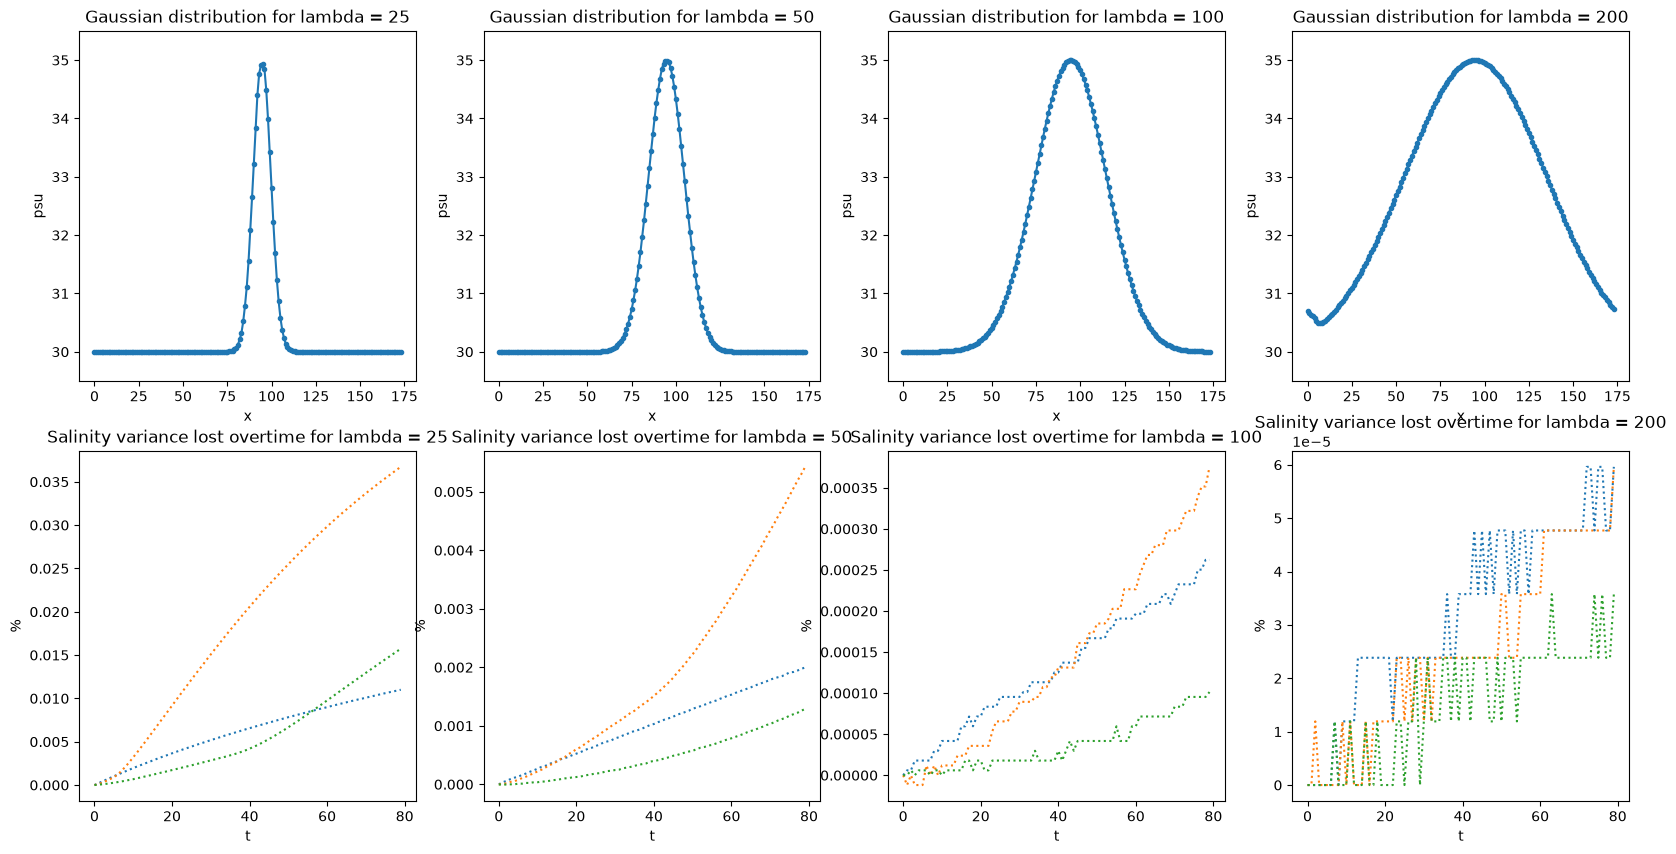

In [70]:
fig_salt2c, axes_salt2c = plt.subplots(2, len(lambda_list), figsize=(20,10)) 

for i, l in enumerate(lambda_list):
        for scheme in scheme_list :
            dataset = xr.open_dataset(rep+'CANAL_gauss_'+scheme+'.'+str(l)+'_all_grid.nc', decode_times=False)
            s2c = dataset['salt2c'].mean(dim=('x_grid_T', 'y_grid_T'))
            s2c = np.array(s2c)
            tot = s2c[0]
            data = (1-s2c/s2c[0])*100
            time = np.arange(s2c.shape[0])
            axes_salt2c[1][i].plot(time,  data, ':', label = scheme)#trace le pourcentage 1-le ratio sur la valeur initiale
            #axes_salt2c[1][i].set_ylim(0,0.035)
            axes_salt2c[1][i].set_title(f"Salinity variance lost overtime for lambda = {l}")
            axes_salt2c[1][i].set_xlabel('t')
            axes_salt2c[1][i].set_ylabel('%')
        gauss = dataset['soce'].isel(time_counter=0, y_grid_T = 50, deptht=0)
        x = np.arange(gauss.shape[0])
        axes_salt2c[0][i].plot(x, gauss, '.-')
        axes_salt2c[0][i].set_title(f"Gaussian distribution for lambda = {l}")
        axes_salt2c[0][i].set_ylim(29.5,35.5)
        axes_salt2c[0][i].set_xlabel('x')
        axes_salt2c[0][i].set_ylabel('psu')
    


La forme des plots est irreguliere et a change. Quand on regarde l'axe des y, on remarque que c'est parce que les valeurs sont tres petites, et tres zoomee. J'ai essaye de dezoomer mais ca ne rend pas bien non plus parce que tout est ecrase.
Normalemement il n'y a pas une vraie source, c'est juste qu'en reduisant dx et dy on a ameliore la conservation de la salinite. Les pertes deviennent plus petites et du coup c'est "moins beau"

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_cen2``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

In [71]:
cen2 = xr.open_dataset(rep+'CANAL_gauss_cen2.100_all_grid.nc', decode_times=False)
#cen4 = xr.open_dataset(rep+'CANAL_gauss_cen4.100_all_grid.nc', decode_times=False)
ubs = xr.open_dataset(rep+'CANAL_gauss_ubs.100_all_grid.nc', decode_times=False)
fct2 = xr.open_dataset(rep+'CANAL_gauss_fct2.100_all_grid.nc', decode_times=False)
fct4 = xr.open_dataset(rep+'CANAL_gauss_fct4.100_all_grid.nc', decode_times=False)

FileNotFoundError: [Errno 2] No such file or directory: '/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00/CANAL_gauss_cen4.100_all_grid.nc'

A dispersive scheme such as CEN causes different frequency components of a wave to travel at incorrect and varying speeds, creating spurious wiggles or phase shifts. The oscillations of values of the salinity tracer you should see around the edges of the block are symptomatic of the incorrect propagation occuring in a dispersive scheme. 

A consequence of these oscillations due to discontinuous data is the Gibbs Phenomenon where high-order linear schemes attempting to resolve a sharp step will always produce an overshoot/undershoot 
near the discontinuity if they lack sufficient numerical diffusion to damp them out.

Areas where overshoot/undershoot are produced should appear in yellow.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .false. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .false. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .true.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_ubs``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

The UBS scheme is not positive either, meaning that false extrema (highlighted in yellow above) are permitted, but the amplitude of such are significantly reduced compared to CEN2 as shown below.

The UBS scheme is not positive either, meaning that false extrema (highlighted in yellow above) are permitted, but the amplitude of such are significantly reduced compared to CEN2 as shown below.

## Corrected scheme 

### Running the simulation

An example of a corrected scheme in NEMO 5.0 is the Flux Corrected Transport scheme (FCT).
To run a FCT simulation, we need to change ```ln_traadv_fct``` from ```.false.``` to ```.true.``` and the ```nn_fct_h``` and ```nn_fct_v``` from ```4``` to ```2``` in the namelist.

__To make the recquired changes you can either modify the files yourself by following the instructions starting 2 cells below or you can execute the cell below__

```
&namtra_adv    !   advection scheme for tracer                          (default: NO selection)
!-----------------------------------------------------------------------
   ln_traadv_OFF = .false. !  No tracer advection
   ln_traadv_cen = .false. !  2nd order centered scheme
      nn_cen_h   =  2            !  =2/4, horizontal 2nd order CEN / 4th order CEN
      nn_cen_v   =  2            !  =2/4, vertical   2nd order CEN / 4th order COMPACT
   ln_traadv_fct = .true. !  FCT scheme
      nn_fct_h   =  2            !  =2/4, horizontal 2nd / 4th order
      nn_fct_v   =  2            !  =2/4, vertical   2nd / COMPACT 4th order
   ln_traadv_mus = .false. !  MUSCL scheme
      ln_mus_ups = .false.       !  use upstream scheme near river mouths
   ln_traadv_ubs = .false.  !  UBS scheme
      nn_ubs_v   =  2            !  =2  , vertical 2nd order FCT / COMPACT 4th order
   ln_traadv_qck = .false. !  QUICKEST scheme
/```

Change the name of the experience ```cn_exp``` from ```CANAL_saltblock``` to ```CANAL_saltblock_fct2``` so as not to overwrite the data when running other simulations later on.

We can now run the simulation using the ./run_nemo command

### Analysis of the outcome

The diffusive scheme is activated when a local extremum is produced and it is used to corrects the side lobe. That is why we should not see values over the maximum initial value of salinity or values under the mininum initial value of salinity.

## Comparative plots

In [6]:
gauss_0 = xr.open_dataset(rep+'CANAL_gauss_traadvOFF.100_all_grid.nc', decode_times=False)
gauss_0 =gauss_0.soce.isel(y_grid_T = 50, time_counter=0, deptht=0)

v= 0.5
dx = 5000
ref = []

for t in range (80):
    ref.append(np.roll(gauss_0, shift=v*86400*(t+1)/dx))
    
print(ref[0].shape)

(174,)


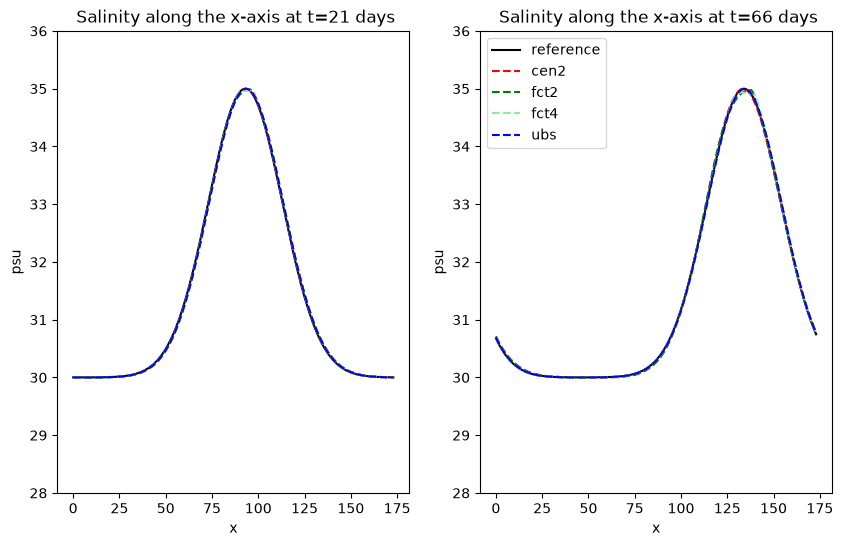

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10,6))

ax[0].plot(np.arange(len(ref[0])), ref[20], color ='black', label ='reference')
ax[0].plot(np.arange(cen2['soce'].shape[3]), cen2['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='red', label = 'cen2')
#ax[0].plot(np.arange(cen4['soce'].shape[3]), cen4['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='orange', label ='cen4')
ax[0].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=20, y_grid_T=50, deptht=0), '--', color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_ylim(28,36)
ax[0].set_title(f' Salinity along the x-axis at t=21 days')

ax[1].plot(np.arange(len(ref[0])), ref[65], color ='black', label ='reference')
ax[1].plot(np.arange(cen2['soce'].shape[3]), cen2['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='red', label = 'cen2')
#ax[1].plot(np.arange(cen4['soce'].shape[3]), cen4['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='orange', label ='cen4')
ax[1].plot(np.arange(fct2['soce'].shape[3]), fct2['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['soce'].shape[3]), fct4['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['soce'].shape[3]), ubs['soce'].isel(time_counter=65, y_grid_T=50, deptht=0), '--', color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_ylim(28,36)
ax[1].set_title(f' Salinity along the x-axis at t=66 days')

plt.legend()


In [73]:
gauss_0 = xr.open_dataset(rep+'CANAL_gauss_traadvOFF.100_all_grid.nc').sssgrad.isel(y_grid_T = 50, time_counter = 0)

ref_grad = []

for t in range (80):
    ref_grad.append(np.roll(gauss_0, shift=v*86400*(t+0.5)/dx)) # 
"""ce 0.5 me pose probleme, cela veut dire que soit la sortie 
        est prise en milieu de journee pas en fin de journee comme on avait convenu
        normalement ce n'est pas la moyenne de la journee c'est sur car j'ai bien verifie 
        dans def_field qu'on etait en operation=instant"""
print(ref[0].shape)

(174,)


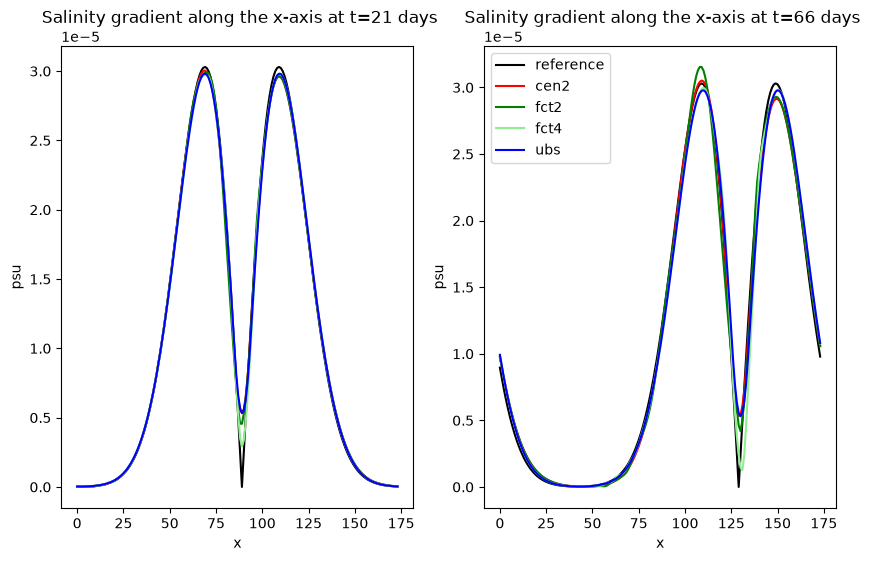

In [74]:
fig, ax = plt.subplots(1, 2, figsize=(10,6))

ax[0].plot(np.arange(len(ref_grad[0])), ref_grad[20], color ='black', label ='reference')
ax[0].plot(np.arange(cen2['sssgrad'].shape[2]), cen2['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='red', label = 'cen2')
#ax[0].plot(np.arange(cen4['sssgrad'].shape[2]), cen4['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='orange', label ='cen4')
ax[0].plot(np.arange(fct2['sssgrad'].shape[2]), fct2['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='green', label = 'fct2')
ax[0].plot(np.arange(fct4['sssgrad'].shape[2]), fct4['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='lightgreen', label = 'fct4')
ax[0].plot(np.arange(ubs['sssgrad'].shape[2]), ubs['sssgrad'].isel(time_counter=20, y_grid_T=50), color ='blue', label ='ubs')
ax[0].set_xlabel('x')
ax[0].set_ylabel('psu')
ax[0].set_title(f' Salinity gradient along the x-axis at t=21 days')

ax[1].plot(np.arange(len(ref_grad[0])), ref_grad[65], color ='black', label ='reference')
ax[1].plot(np.arange(cen2['sssgrad'].shape[2]), cen2['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='red', label = 'cen2')
#ax[1].plot(np.arange(cen4['sssgrad'].shape[2]), cen4['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='orange', label ='cen4')
ax[1].plot(np.arange(fct2['sssgrad'].shape[2]), fct2['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='green', label = 'fct2')
ax[1].plot(np.arange(fct4['sssgrad'].shape[2]), fct4['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='lightgreen', label = 'fct4')
ax[1].plot(np.arange(ubs['sssgrad'].shape[2]), ubs['sssgrad'].isel(time_counter=65, y_grid_T=50), color ='blue', label = 'ubs')
ax[1].set_xlabel('x')
ax[1].set_ylabel('psu')
ax[1].set_title(f' Salinity gradient along the x-axis at t=66 days')

plt.legend()

To better visualize the oscillations of the CEN2 signal let us trace the salinity of one fixed point in space through time.You should see oscillations near discontinuities. These represent the different frequency components of the square wave traveling at incorrect and varying speeds

For the UBS graph, the artefacts of the dispersive component are the oscillations near the sharp edges, the drops below 30 and the values over 35. The artecfacts of the diffusive components are the peaks and sharp edges being smoothed out. As the effect of the dispersive component counters the effect of the diffusive component (the oscillations produced by the the dispersive component are smoothed out by the diffusive component), it is quite difficult to make a diagnosis out of the figure other than the overshoot/undershoot.

Similarly to the UBS scheme, a "dampening", a flattening of the sharp peaks of the FCT2 square wave should be seen. As the side lobes are automatically fully corrected as soon as they appear they cannot spread oscillations.

We do not see the periodic peaks that represent the front and the back of the square because the CEN2 scheme distorted the shape of the square. 

The amplitude of high magnitude gradients for UBS and FCT2 should decay (dampening effect) compared to the CEN2 graph.

Contrary to dispersive schemes, diffusive schemes are non-positive, the tracer variance should systematically decrease (dissipation). As the front of the square is very abrupt ir encourages the formation of side-lobes. The FCT2 first order dispersive scheme is largely sollicitated to correct the side lobes created, the scheme falls to first order in this specific example, which is why it sits so far below the UBS graph. For similar reasons FCT4 falls to 3rd order.

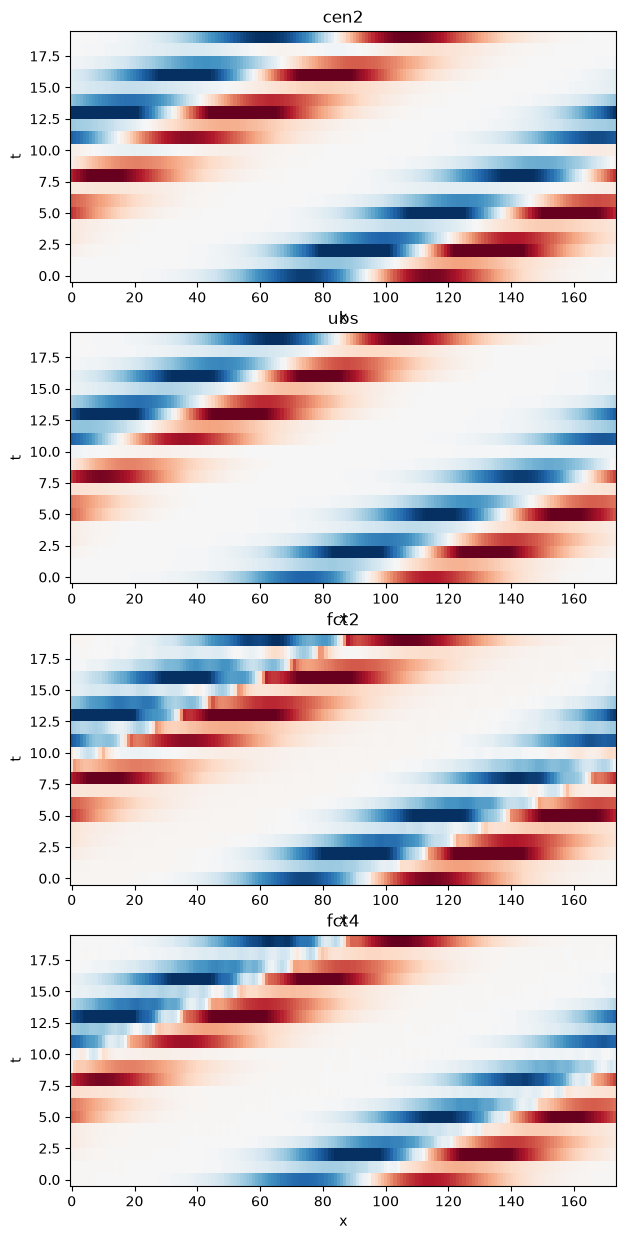

In [84]:
scheme = [cen2, ubs, fct2, fct4]
scheme_str = [ 'cen2', 'ubs', 'fct2', 'fct4']
fig, axes = plt.subplots(len(scheme), 1, figsize=(12, 15))

for n, s in enumerate(scheme):
    plot = []
    for t, date in enumerate(cen2['time_counter'][:20]) : 
        plot.append(s['soce'].isel(y_grid_T = 50, time_counter = t, deptht=0)-ref[t])
    im = axes[n].imshow(plot, origin='lower',  interpolation='nearest', cmap = 'RdBu_r', aspect=4, vmin=plot[-1].min(), vmax=plot[-1].max())
    axes[n].set_title(f"{scheme_str[n]}")
    axes[n].set_xlabel('x')
    axes[n].set_ylabel('t')
    #fig.colorbar(im, ax=axes[n], label='Value Scale')


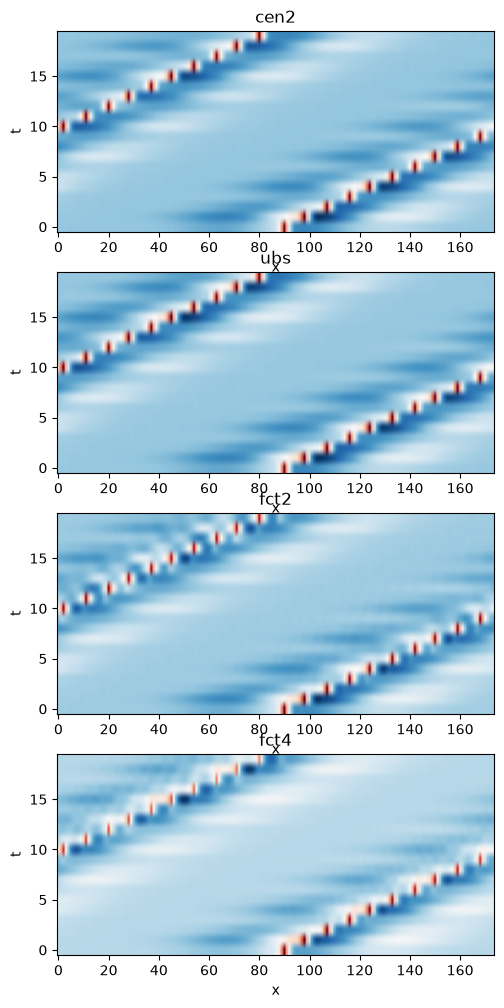

In [76]:
scheme = [cen2, ubs, fct2, fct4]
scheme_str = ['cen2', 'ubs', 'fct2', 'fct4']
fig, axes = plt.subplots(len(scheme), 1, figsize=(15, 12))

vmax = np.nanpercentile(np.concatenate([a.ravel() for a in scheme]), 99)

for n, s in enumerate(scheme):
    plot = []
    for t, date in enumerate(cen2['time_counter'][:20]) : 
        plot.append(s['sssgrad'].isel(y_grid_T = 50, time_counter = t)-ref_grad[t])
    im = axes[n].imshow(plot, origin='lower', cmap = 'RdBu_r',  aspect=4)
    axes[n].set_title(f"{scheme_str[n]}")
    axes[n].set_xlabel('x')
    axes[n].set_ylabel('t')

In [59]:
cen2.close()
ubs.close()
fct2.close()

In [124]:
%%bash 

#Insert below the directory path in which you will run the simulations
#It should look like so : /.../EXP$$

DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00

cd /"$DIR"

bash /"$DIR"/demo_gauss/end_gauss.sh "$DIR"

+ '[' 1 -lt 1 ']'
+ DIR=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/EXP00
+ DIR_PARENT=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42
+ SRC=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90
+ TMP=/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.tmp
+ '[' '!' -f /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 ']'
+ awk '
/pts\(:,:,jk,jp_sal\).*EXP.*rn_lambda/ {next}
{print}
' /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90
+ diff /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.tmp
+ cp /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90 /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak
+ mv /Users/jbuisson

Changes applied. Saving : /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC/usrdef_istate.F90.bak


+ cd /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo
+ echo Compiling
+ ./makenemo -r CANAL -n EXP42


Compiling
-e 



You are compiling an existing configuration EXP42 with sub-components: OCE


Creating /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK = /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/src/OCE for EXP42

/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/MY_SRC content is linked to /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/WORK

--------------------------------------------------------------------------------
Compilation
--------------------------------------------------------------------------------

Build command started on Thu Oct  8 15:16:39 2026.
->Parse configuration: start
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/bld.cfg
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/arch_nemo.fcm
Config file (bld): /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/cpp.fcm
->Parse configuration: 1 second
->Setup destination: start
De

Use of uninitialized value in numeric gt (>) at /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/ext/FCM/bin/../lib/Fcm/BuildTask.pm line 176.


No. of pre-processed file: 1
->Pre-process: 0 second
->Scan dependency: start
No. of file scanned for dependency: 1
/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/Makefile: updated
->Scan dependency: 0 second
->Generate Fortran interface: start
->Generate Fortran interface: 0 second
->Make: start
mpif90-mpich-gcc15 -o usrdef_istate.o -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/inc -fdefault-real-8 -march=native -O2 -fno-expensive-optimizations -funroll-all-loops -fcray-pointer -ffree-line-length-none -fallow-argument-mismatch -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/inc -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/include -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/include -c /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/ppsrc/nemo/usrdef_istate.f90
mpif90-mpich-gcc15 -o restart.o -I/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/inc -fdefault-real-8 -march=native 

ar: creating archive /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(cyclone.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(defprec.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(ioipsl.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(obs_const.o) has no symbols
/Library/Developer/CommandLineTools/usr/bin/ranlib: file: /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/tmp/lib__fcm__nemo.a(par_kind.o) has no symbols
/Library/Developer/CommandLineTools

mpif90-mpich-gcc15 -o nemo.exe /Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/obj/nemo.o -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/nemo/tests/EXP42/BLD/lib -l__fcm__nemo -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -Wl,-rpath,/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/lib -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/xios-3.0.x/lib -lxios -lstdc++ -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lnetcdff -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lnetcdf -L/Users/jbuisson/ALL_NEMO_macport_mpich_gcc15/util_nemo/lib -lhdf5_hl -lhdf5 -L/opt/local/lib -lcurl  -lz  -lm
->Make: 113 seconds
->TOTAL: 114 seconds
Build command finished on Thu Oct  8 15:18:33 2026.

--------------------------------------------------------------------------------
Compilation successful
------------------------------------------------------------------